<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/tp_mpg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importamos todas las librerías necesarias
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# **1 - Exploración de los datos del dataset AirBnB Milan**

## **1.1 - CARGA DEL DATASET**

In [ ]:
# Download latest version
RAW_DATA_PATH = kagglehub.dataset_download("antoniokaggle/milan-airbnb-open-data-only-entire-apartments")

print("Path to dataset files:", RAW_DATA_PATH)

Using Colab cache for faster access to the 'milan-airbnb-open-data-only-entire-apartments' dataset.
Path to dataset files: /kaggle/input/milan-airbnb-open-data-only-entire-apartments


In [ ]:
df_raw = pd.read_csv(Path(RAW_DATA_PATH) / "Airbnb_Milan.csv", index_col=0)
pd.set_option('display.max_columns', len(df_raw.columns)) # Para ver todas las columnas
pd.set_option('display.max_rows', 100)
df_raw

,id,host_id,host_location,host_response_time,host_response_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,zipcode,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,daily_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,TV,WiFi,Air_Condition,Wheelchair_accessible,Kitchen,Breakfast,Elevator,Heating,Washer,Iron,Host_greets_you,Paid_parking_on_premises,Luggage_dropoff_allowed,Long_term_stays_allowed,Doorman,Pets_allowed,Smoking_allowed,Suitable_for_events,24_hour_check_in
1,73892,387110,1,1,57,0,3,1,1,1,20121,45.47015,9.19134,Entire home/apt,2,3,1,1,1,94,1,45,1,0,2,29,59,89,364,84,94,9,9,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
2,74169,268127,1,1,57,0,1,1,0,1,20121,45.47169,9.18412,Entire home/apt,4,3,1,1,1,125,31,30,1,0,2,0,0,9,284,3,100,10,10,10,10,10,9,0,0,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0
3,77958,387110,1,1,57,0,3,1,1,1,20121,45.47117,9.19135,Entire home/apt,2,3,1,1,1,100,1,45,1,0,2,29,59,89,364,70,97,9,10,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
4,93025,499743,1,1,57,0,1,1,0,1,20121,45.47204,9.19640,Entire home/apt,3,3,1,2,1,120,48,57,2,40,2,10,40,70,160,57,97,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0
5,132705,391011,1,1,57,1,2,1,0,1,20135,45.45934,9.20609,Entire home/apt,2,3,0,1,3,70,13,45,1,0,30,27,57,87,362,44,90,9,9,10,10,9,9,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9318,35954783,56584596,1,1,57,0,1,1,1,9,20124,45.48586,9.19706,Entire home/apt,2,3,1,1,1,80,1,1,1,0,1,1,1,1,1,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
9319,36023503,271013325,1,1,57,0,1,1,0,9,20124,45.48170,9.18968,Entire home/apt,6,5,2,2,1,900,1,69,2,30,1,9,9,18,204,2,100,10,10,10,10,10,10,1,0,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0
9320,36071908,271354203,1,0,57,0,1,1,0,9,20159,45.49807,9.18476,Entire home/apt,2,3,1,1,1,70,1,20,1,20,1,30,60,90,365,3,100,9,10,10,10,9,10,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0
9321,36305676,171239896,1,1,40,0,3,1,0,9,20158,45.50107,9.18210,Entire home/apt,4,3,1,2,1,65,1,1,1,0,1,29,59,89,364,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0


In [ ]:
# Ponemos la columna target daily_price al final
col_target = df_raw.pop("daily_price")
df_raw.insert(len(df_raw.columns), col_target.name, col_target)

## **1.2 - Detección de datos duplicados y/o nulos**

In [ ]:
# Verificar si hay valores nulos en el DataFrame
sum(df_raw.isnull().sum())

0

No nulos en ninguna columna

Chequeamos si hay duplicados: nos fijamos por el `id`

In [ ]:
df_raw["id"].nunique() == len(df_raw)

True

No hay repetidos

In [ ]:
# @title


def tabla_frecuencias(df, columnas, valores=None, decimales=2):
    """
    Calcula la distribución porcentual de un conjunto de variables
    que comparten los mismos valores posibles.

    Parámetros
    ----------
    df : pd.DataFrame
        Dataset original.
    columnas : list
        Columnas que se desean analizar.
    valores : list, opcional
        Valores posibles de las variables.
        Si es None, se infieren a partir de las columnas.
    decimales : int
        Cantidad de decimales a mostrar.

    Retorna
    -------
    pd.DataFrame
        Porcentaje de cada valor posible para cada variable.
    """

    # Verificar que las columnas existan
    faltantes = set(columnas) - set(df.columns)
    if faltantes:
        raise ValueError(f"Columnas inexistentes: {faltantes}")

    if not columnas:
        raise ValueError("Se debe indicar al menos una columna.")

    # Inferir valores posibles si no fueron especificados
    if valores is None:
        valores = pd.unique(
            pd.concat([df[col] for col in columnas]).dropna()
        ).tolist()
    else:
        valores = list(valores)

    # Verificar que todas las columnas contengan valores válidos
    for col in columnas:
        invalidos = df.loc[
            df[col].notna() & ~df[col].isin(valores), col
        ].unique()

        if len(invalidos) > 0:
            raise ValueError(
                f"La columna '{col}' contiene valores "
                f"no permitidos: {invalidos}"
            )

        if df[col].notna().sum() == 0:
            raise ValueError(
                f"La columna '{col}' no contiene valores válidos."
            )

    # Calcular frecuencias relativas porcentuales
    tabla = pd.DataFrame({
        col: df[col].value_counts(normalize=True)
                     .reindex(valores, fill_value=0) * 100
        for col in columnas
    }).T

    tabla.index.name = "Variable"
    tabla.columns.name = "Valor"

    return tabla.round(decimales)


## 1.3 - **Descripción del dataset: Milan Airbnb y Selección de Features**

El dataset contiene información sobre alojamientos publicados en Airbnb en la ciudad de Milán (Italia), considerando únicamente propiedades que se alquilan completas.

El objetivo del problema de regresión es **predecir el precio por noche (`daily_price`)** a partir de las características de los alojamientos, sus anfitriones, ubicación, disponibilidad y evaluaciones.




### 0) Target: precio diario

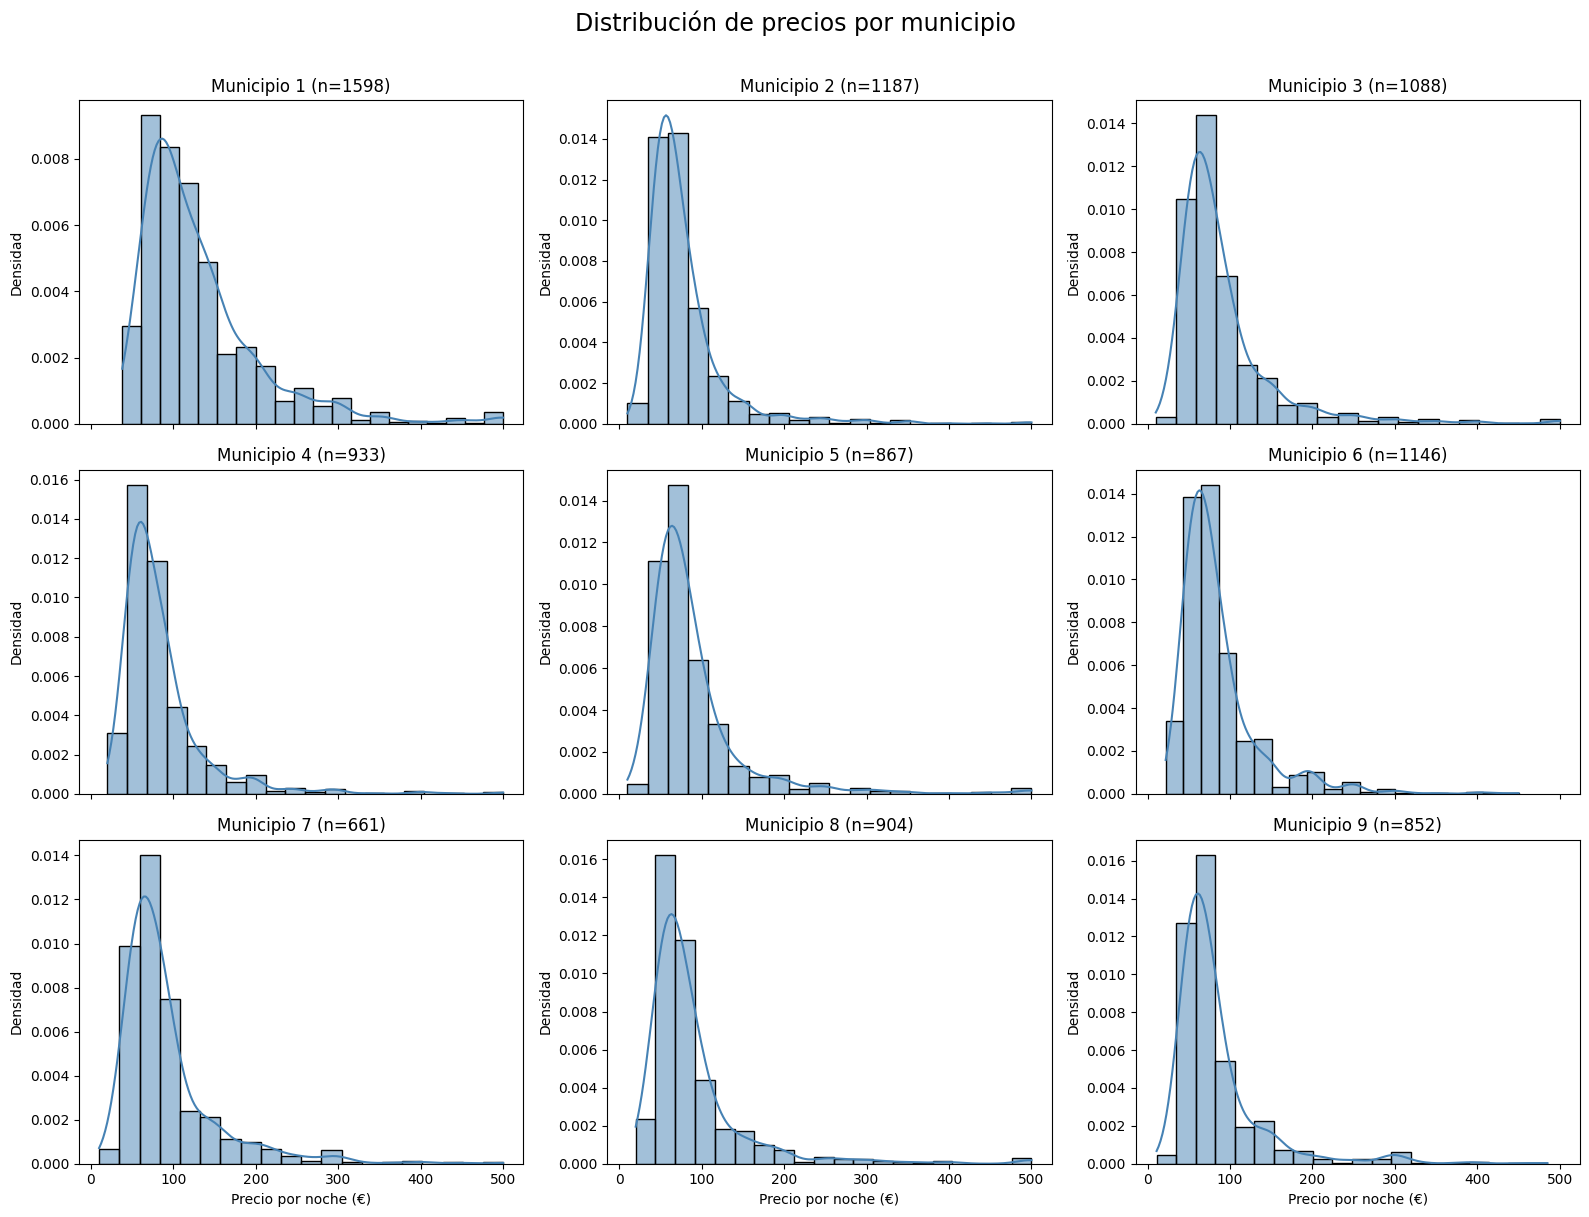

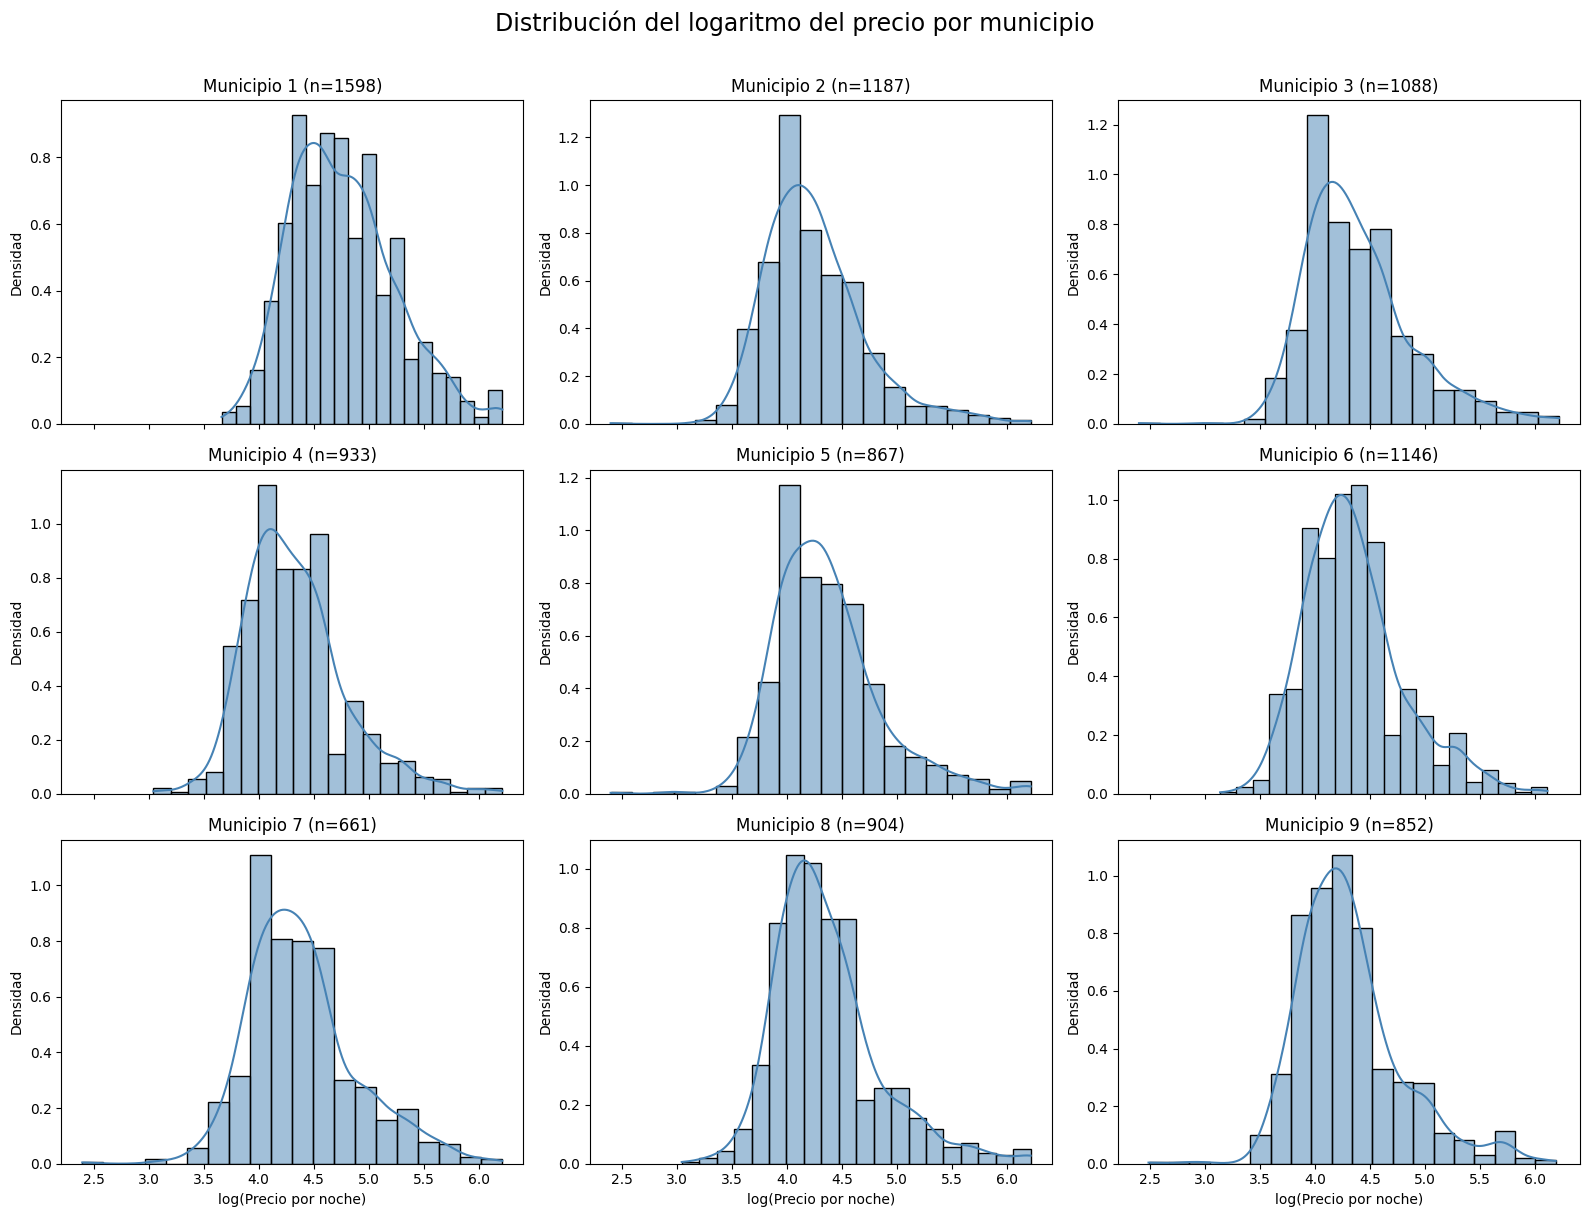

In [ ]:
# @title
from math import ceil

# Preparación de los datos
data = df_raw[
    ["neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# El logaritmo requiere precios positivos
data = data[data["daily_price"] > 0]

# Excluir el 1% de precios más altos solo para visualizar
limite = data["daily_price"].quantile(0.99)
data = data[data["daily_price"] <= limite].copy()

# Transformación logarítmica
data["log_daily_price"] = np.log1p(data["daily_price"])

# Municipios
municipios = sorted(data["neighbourhood_cleansed"].unique())


def plot_histogramas_por_municipio(columna, titulo, xlabel):
    n_cols = 3
    n_rows = ceil(len(municipios) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        sharex=True
    )

    axes = np.array(axes).flatten()

    for ax, municipio in zip(axes, municipios):
        subset = data[
            data["neighbourhood_cleansed"] == municipio
        ]

        sns.histplot(
            data=subset,
            x=columna,
            bins=20,
            kde=True,
            stat="density",
            color="steelblue",
            ax=ax
        )

        ax.set_title(
            f"Municipio {municipio} (n={len(subset)})"
        )
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Densidad")

    # Eliminar ejes sobrantes
    for ax in axes[len(municipios):]:
        ax.remove()

    fig.suptitle(titulo, fontsize=17, y=1.01)
    plt.tight_layout()
    plt.show()


# Figura 1: precios originales
plot_histogramas_por_municipio(
    "daily_price",
    "Distribución de precios por municipio",
    "Precio por noche (€)"
)

# Figura 2: logaritmo de los precios
plot_histogramas_por_municipio(
    "log_daily_price",
    "Distribución del logaritmo del precio por municipio",
    "log(Precio por noche)"
)

Vemos que el precio tiene una distribución aproximada lognormal

In [ ]:
df_raw["log_daily_price"] = np.log1p(df_raw["daily_price"]) # log(1+x) para que sea positivo

In [ ]:
df_raw["log_daily_price"].describe()

,log_daily_price
count,9322.000000
mean,4.436873
std,0.551572
min,2.397895
25%,4.094345
50%,4.330733
75%,4.682131
max,8.006701


### 1) Identificación e información del anfitrión

- **`id`**: Identificador único del apartamento.
- **`host_id`**: Identificador único del anfitrión.
- **`host_location`**: Indica si el anfitrión reside en Italia. `1 = Italia`, `0 = fuera de Italia`.
- **`host_response_time`**: Indica la rapidez de respuesta del anfitrión. `1 = rápida`, `0 = lenta`.
- **`host_response_rate`**: Porcentaje de consultas respondidas por el anfitrión.
- **`host_is_superhost`**: Indica si el anfitrión tiene la categoría Superhost. `1 = sí`, `0 = no`.
- **`host_total_listings_count`**: Cantidad total de propiedades publicadas por el anfitrión.
- **`host_has_profile_pic`**: Indica si el anfitrión tiene una foto de perfil. `1 = sí`, `0 = no`.
- **`host_identity_verified`**: Indica si Airbnb verificó la identidad del anfitrión. `1 = sí`, `0 = no`.

In [ ]:
tabla_frecuencias(df_raw, ["host_location", "host_is_superhost"])

Valor,1,0
Variable,,
host_location,95.96,4.04
host_is_superhost,28.89,71.11


Vemos que la gran mayoría son de italia, de modo que **no consideraremos la columa `host_location`**

Se conservan `host_is_superhost` y `host_total_listings_count` para representar la experiencia o escala de actividad del anfitrión sin utilizar su identificador.

### 2) Ubicación del alojamiento




- **`neighbourhood_cleansed`**: Barrio o zona de la ciudad donde se encuentra el alojamiento, según la clasificación normalizada de Airbnb.
- **`zipcode`**: Código postal del alojamiento.
- **`latitude`**: Latitud geográfica del alojamiento.
- **`longitude`**: Longitud geográfica del alojamiento.

Variable eliminada:

- zipcode: código postal del alojamiento.

Variables conservadas:

- neighbourhood_cleansed
- latitude
- longitude

Justificación: el código postal aporta información geográfica parcialmente redundante con el barrio y las coordenadas. Se prioriza conservar la ubicación exacta mediante latitud y longitud, además del barrio como variable categórica.

Estas variables permiten representar tanto diferencias entre zonas como variaciones espaciales dentro de ellas.

In [ ]:
UBICACION_DROP_COLUMNS = ["zipcode"]

### 3) Características del alojamiento


- **`room_type`**: Tipo de alojamiento ofrecido. En este dataset se consideran únicamente apartamentos o viviendas completas.
- **`accommodates`**: Cantidad máxima de huéspedes que puede alojar la propiedad.
- **`bathrooms`**: Cantidad de baños del alojamiento.
- **`bedrooms`**: Cantidad de dormitorios del alojamiento.
- **`beds`**: Cantidad de camas disponibles.
- **`bed_type`**: Tipo de cama ofrecida, representado mediante categorías.


In [ ]:
display(df_raw["room_type"].value_counts(normalize=True))
display(df_raw["bed_type"].value_counts(normalize=True))

,proportion
room_type,
Entire home/apt,1.0


,proportion
bed_type,
1,0.975220
2,0.021991
3,0.001824
4,0.000536
5,0.000429


Variable eliminadas:
- `room_type`: El dataset contiene únicamente propiedades completas, por lo que esta variable no presenta variabilidad y no permite diferenciar observaciones.
- `bed_type`: vemos que en su gran mayoría contiene un solo tipo de cama


In [ ]:
CARACTERISTICAS_ALOJAMIENTO_DROP_COLUMNS = ["room_type", "bed_type"]


### 4) Precios y condiciones de reserva





- **`daily_price`**: Precio de alquiler por noche. **Variable objetivo de la regresión.**
- **`security_deposit`**: Depósito de garantía solicitado por el anfitrión.
- **`cleaning_fee`**: Cargo adicional por limpieza del alojamiento.
- **`guests_included`**: Cantidad de huéspedes incluidos en el precio base.
- **`extra_people`**: Cargo adicional por cada huésped extra.
- **`minimum_nights`**: Cantidad mínima de noches exigida para reservar el alojamiento.

Variables eliminadas:

- `security_deposit`: depósito de garantía establecido por el anfitrión.
- `cleaning_fee`: cargo adicional de limpieza.
- `extra_people`: tarifa adicional por huésped extra.

Justificación: estas variables forman parte de la estructura de precios definida por el anfitrión y pueden estar estrechamente relacionadas con el propio daily_price.

Se decide excluirlas para que el modelo estime el precio por noche principalmente a partir de características del alojamiento, y no de otros importes fijados simultáneamente por el anfitrión.

Esto no implica necesariamente que constituyan data leakage, sino que responde al enfoque elegido para el problema de predicción.

Se conservan minimum_nights y guests_included, ya que describen condiciones de reserva que pueden influir en el precio base.

### 5) Disponibilidad




- ❌**`availability_30`**: Cantidad de días disponibles para reservar durante los próximos 30 días.
- ❌**`availability_60`**: Cantidad de días disponibles para reservar durante los próximos 60 días.
- ❌**`availability_90`**: Cantidad de días disponibles para reservar durante los próximos 90 días.
- ✅**`availability_365`**: Cantidad de días disponibles para reservar durante los próximos 365 días.

Justificación: las cuatro variables describen la disponibilidad del mismo alojamiento utilizando diferentes horizontes temporales, por lo que presentan información parcialmente superpuesta.

Para reducir la redundancia y la cantidad de variables, se decide conservar únicamente `availability_365`, que resume la disponibilidadlo largo de un período más amplio.

Cabe destacar que la disponibilidad no equivale directamente a la ocupación, ya que los días no disponibles pueden corresponder a reservas o bloqueos del calendario

### 6) Reseñas y evaluaciones

- ✅**`number_of_reviews`**: Cantidad total de reseñas recibidas por el alojamiento.
- ❌**`review_scores_rating`**: Puntuación general del alojamiento otorgada por los huéspedes (escala de 0 a 100).
- ❌**`review_scores_accuracy`**: Puntuación sobre qué tan precisa es la descripción del alojamiento (0 a 10).
- ❌**`review_scores_cleanliness`**: Puntuación de limpieza del alojamiento (0 a 10).
- ❌**`review_scores_checkin`**: Puntuación del proceso de ingreso o check-in (0 a 10).
- ❌**`review_scores_communication`**: Puntuación de la comunicación con el anfitrión (0 a 10).
- ❌**`review_scores_location`**: Puntuación de la ubicación del alojamiento (0 a 10).
- ✅**`review_scores_value`**: Puntuación de la relación calidad-precio del alojamiento (0 a 10).



Justificación: para simplificar el modelo, se utiliza la puntuación general como indicador resumido de la satisfacción de los huéspedes, evitando incorporar todas las evaluaciones individuales, que pueden presentar correlaciones importantes.

Se elimina específicamente review_scores_value porque mide la percepción de la relación calidad-precio, la cual depende parcialmente del precio que se intenta predecir.

### 7) Políticas y condiciones adicionales ❌

- **`instant_bookable`**: Indica si el alojamiento permite realizar reservas instantáneas sin aprobación previa del anfitrión.
- **`cancellation_policy`**: Tipo de política de cancelación establecida por el anfitrión.
- **`require_guest_profile_picture`**: Indica si se exige que el huésped tenga una foto de perfil.
- **`require_guest_phone_verification`**: Indica si se exige que el huésped tenga su número telefónico verificado.



Se eliminan todas estas, ya que no depende del alojamiento en si, sino del anfitrion

### 8) Servicios y comodidades

Las siguientes variables son binarias: `1 = disponible/permitido`, `0 = no disponible/no permitido`.

- **`TV`**: Disponibilidad de televisión.
- **`WiFi`**: Disponibilidad de conexión inalámbrica a Internet.
- **`Air_Condition`**: Disponibilidad de aire acondicionado.
- **`Wheelchair_accessible`**: Accesibilidad para personas que utilizan silla de ruedas.
- **`Kitchen`**: Disponibilidad de cocina.
- **`Breakfast`**: Desayuno incluido u ofrecido.
- **`Elevator`**: Disponibilidad de ascensor.
- **`Heating`**: Disponibilidad de calefacción.
- **`Washer`**: Disponibilidad de lavarropas.
- **`Iron`**: Disponibilidad de plancha.
- **`Host_greets_you`**: Indica si el anfitrión recibe personalmente a los huéspedes.
- **`Paid_parking_on_premises`**: Disponibilidad de estacionamiento pago dentro de la propiedad.
- **`Luggage_dropoff_allowed`**: Posibilidad de dejar el equipaje antes del check-in o después del check-out.
- **`Long_term_stays_allowed`**: Indica si se permiten estadías prolongadas.
- **`Doorman`**: Disponibilidad de portero o servicio de recepción.
- **`Pets_allowed`**: Indica si se permiten mascotas.
- **`Smoking_allowed`**: Indica si se permite fumar.
- **`Suitable_for_events`**: Indica si el alojamiento permite organizar eventos.
- **`24_hour_check_in`**: Disponibilidad de ingreso al alojamiento durante las 24 horas.

In [ ]:
AMENITIES = [
    "TV", "WiFi", "Air_Condition", "Wheelchair_accessible", "Kitchen",
    "Breakfast", "Elevator", "Heating", "Washer", "Iron", "Host_greets_you",
    "Paid_parking_on_premises", "Luggage_dropoff_allowed",
    "Long_term_stays_allowed", "Doorman", "Pets_allowed", "Smoking_allowed",
    "Suitable_for_events", "24_hour_check_in"
]
tabla_frecuencias(df_raw, AMENITIES)

Valor,1,0
Variable,,
TV,87.25,12.75
WiFi,92.86,7.14
Air_Condition,72.76,27.24
Wheelchair_accessible,4.22,95.78
Kitchen,96.73,3.27
Breakfast,17.28,82.72
Elevator,61.48,38.52
Heating,98.07,1.93
Washer,81.03,18.97


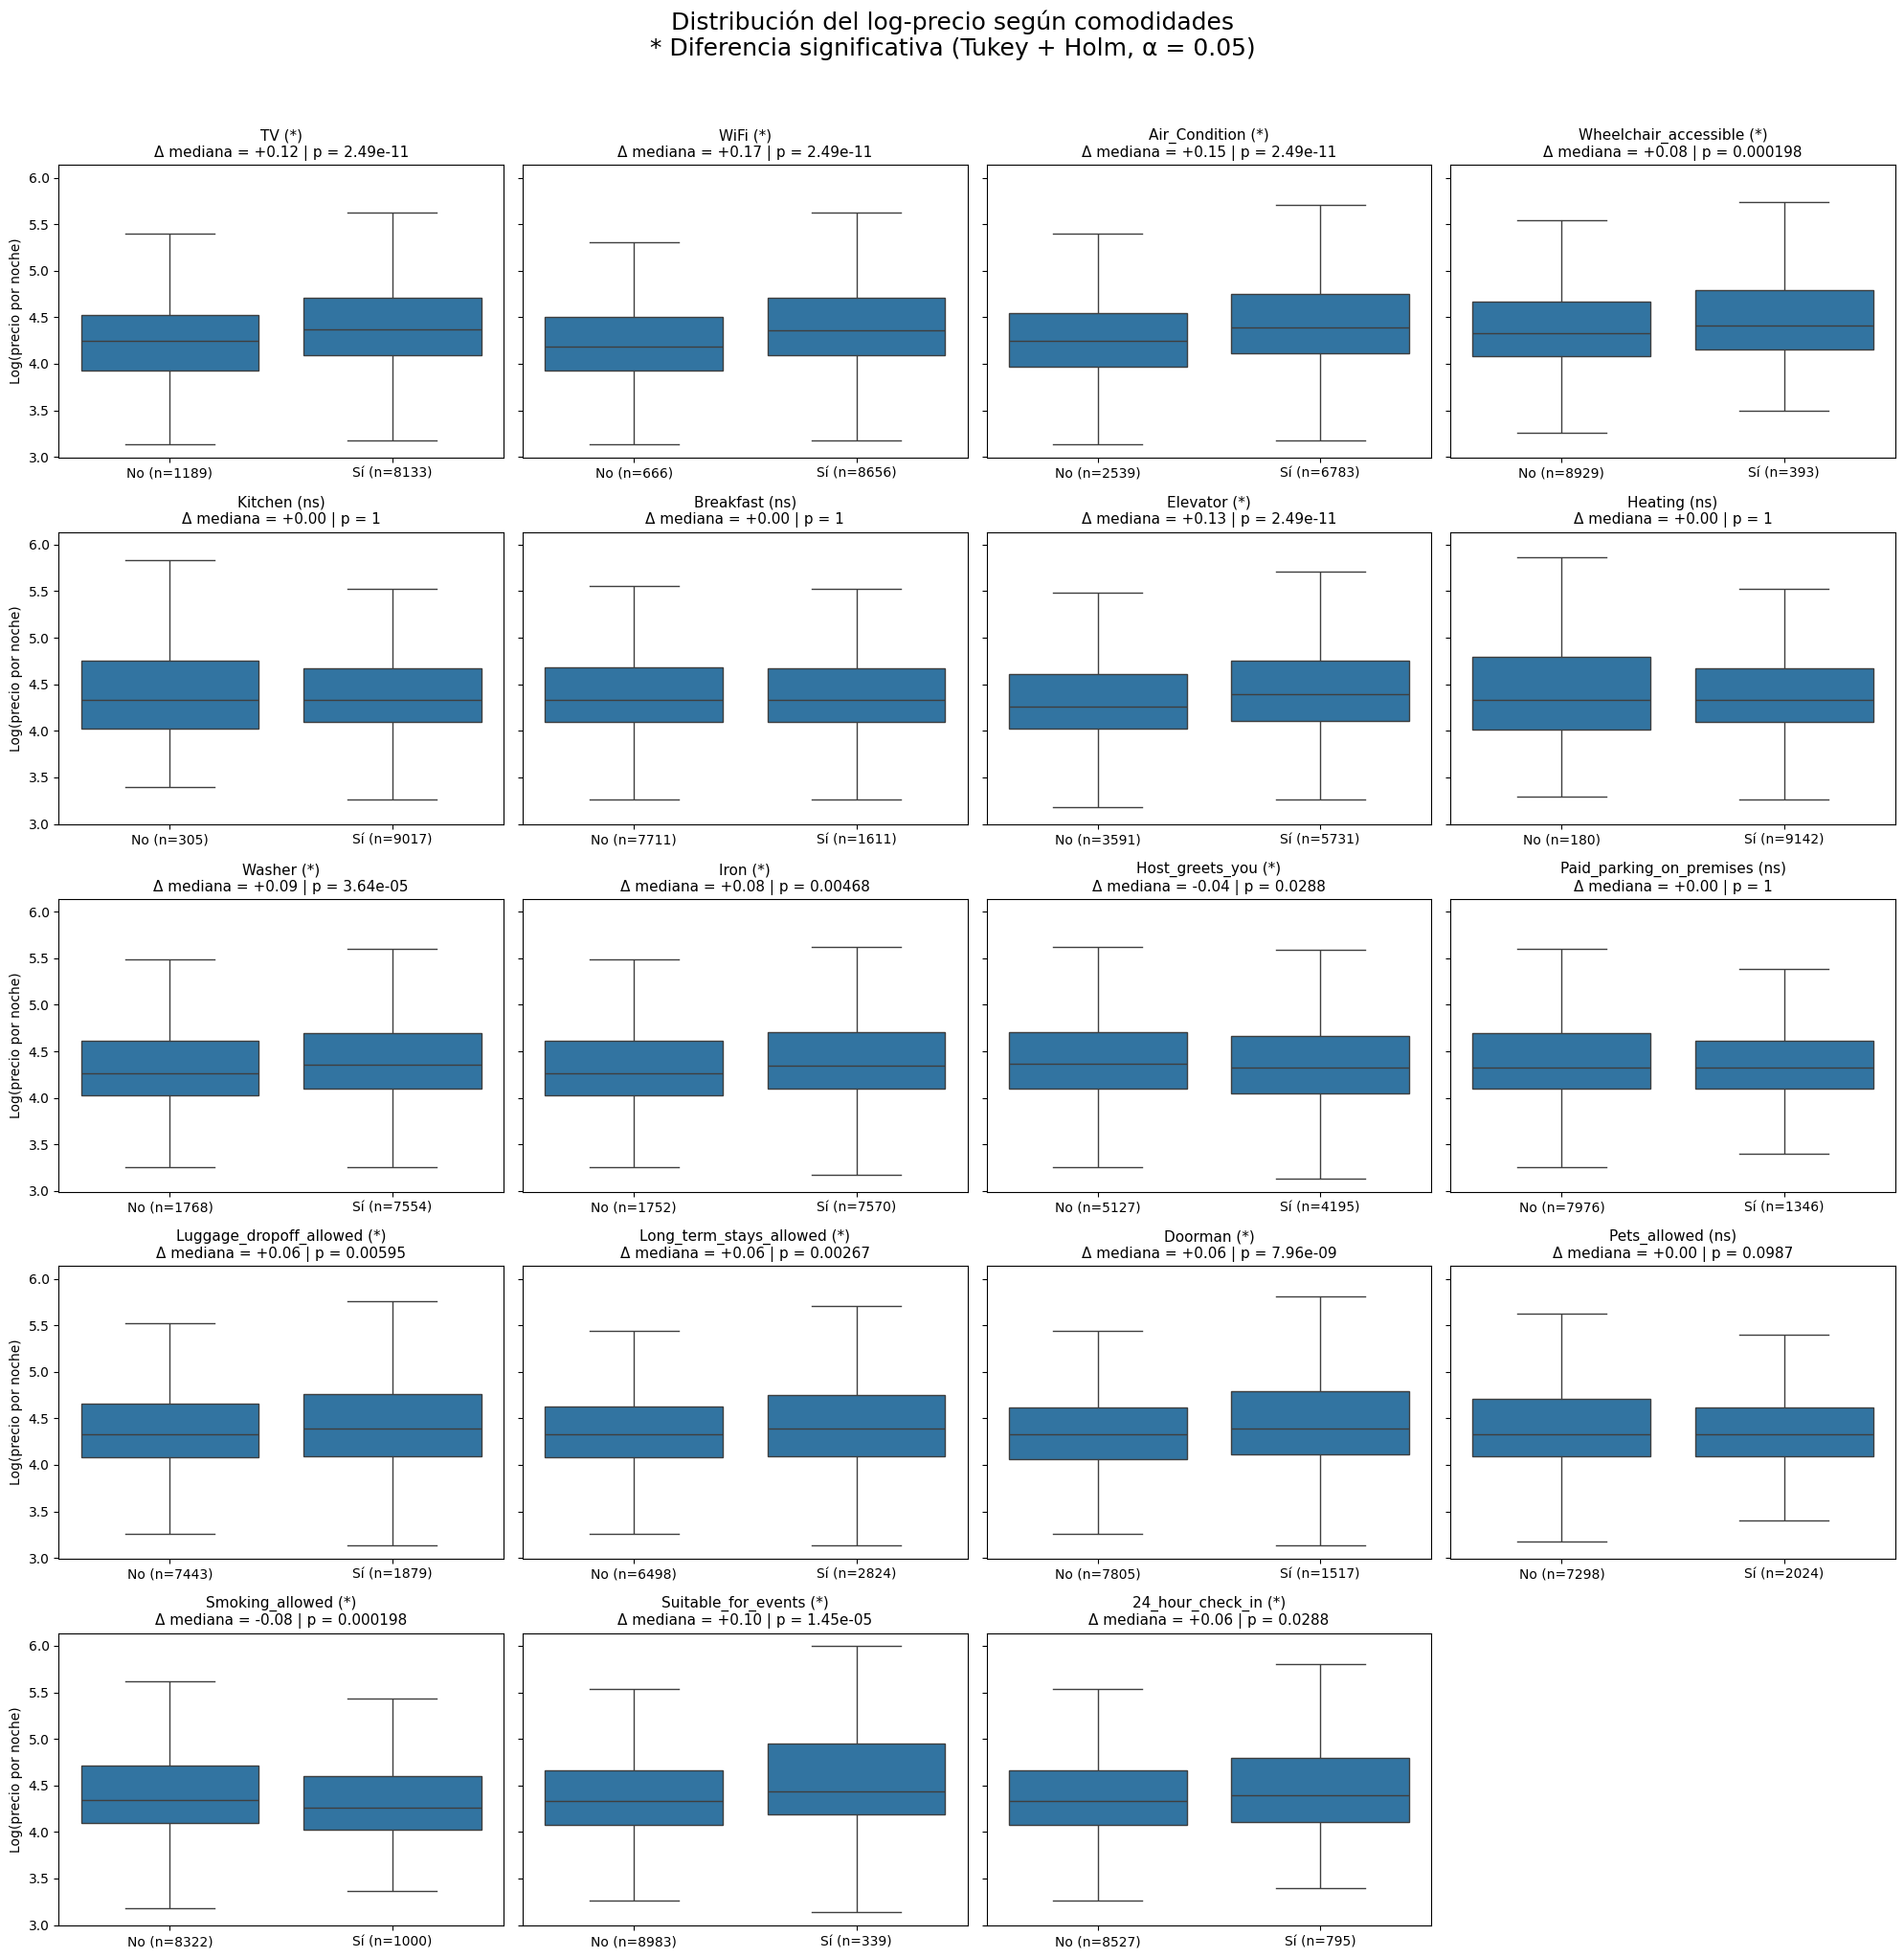

In [ ]:
from statsmodels.stats.multicomp import MultiComparison, pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

alpha = 0.05

# ==========================================
# 1. Test de Tukey para cada comodidad
# ==========================================

resultados = {}

for col in AMENITIES:

    datos = df_raw[[col, "log_daily_price"]].dropna()
    datos = datos[datos[col].isin([0, 1])]

    # Diferencia de medianas
    medianas = datos.groupby(col)["log_daily_price"].median()
    diferencia = medianas.get(1, np.nan) - medianas.get(0, np.nan)

    # Cantidad de observaciones
    counts = datos[col].value_counts()

    # Test de Tukey
    p_value = np.nan

    if counts.get(0, 0) >= 2 and counts.get(1, 0) >= 2:

        tukey = pairwise_tukeyhsd(
            endog=datos["log_daily_price"],
            groups=datos[col],
            alpha=alpha
        )

        # Solo hay una comparación: 0 vs 1
        p_value = tukey.pvalues[0]

        # Equivalente utilizando MultiComparison:
        # tukey = MultiComparison(
        #     datos["log_daily_price"], datos[col]
        # ).tukeyhsd(alpha=alpha)

    resultados[col] = {
        "diferencia": diferencia,
        "counts": counts,
        "p_value": p_value
    }


# ==========================================
# 2. Corrección de Holm (19 tests)
# ==========================================

columnas_validas = [
    col for col in AMENITIES
    if np.isfinite(resultados[col]["p_value"])
]

if columnas_validas:

    reject, p_adjusted, _, _ = multipletests(
        [resultados[col]["p_value"] for col in columnas_validas],
        alpha=alpha,
        method="holm"
    )

    for col, significativo, p_adj in zip(
        columnas_validas, reject, p_adjusted
    ):
        resultados[col]["significativo"] = significativo
        resultados[col]["p_adj"] = p_adj


# ==========================================
# 3. Boxplots
# ==========================================

n_cols = 4
n_rows = int(np.ceil(len(AMENITIES) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    sharey=True
)

axes = axes.flatten()

for ax, col in zip(axes, AMENITIES):

    sns.boxplot(
        data=df_raw,
        x=col,
        y="log_daily_price",
        order=[0, 1],
        showfliers=False,
        ax=ax
    )

    res = resultados[col]

    diferencia = res["diferencia"]
    counts = res["counts"]
    significativo = res.get("significativo", False)
    p_adj = res.get("p_adj", np.nan)

    # Asterisco si es significativo
    marca = "*" if significativo else "ns"

    ax.set_title(
        f"{col} ({marca})\n"
        f"Δ mediana = {diferencia:+.2f} | p = {p_adj:.3g}",
        fontsize=11
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        f"No (n={counts.get(0, 0)})",
        f"Sí (n={counts.get(1, 0)})"
    ])

    ax.set_xlabel("")
    ax.set_ylabel("Log(precio por noche)")

# Eliminar ejes sobrantes
for ax in axes[len(AMENITIES):]:
    ax.remove()

fig.suptitle(
    "Distribución del log-precio según comodidades\n"
    "* Diferencia significativa (Tukey + Holm, α = 0.05)",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

ranking = pd.DataFrame([
    {
        "amenity": col,
        "p_adj": resultados[col].get("p_adj", np.nan),
        "dif_mediana": resultados[col]["diferencia"],
        "n0": resultados[col]["counts"].get(0, 0),
        "n1": resultados[col]["counts"].get(1, 0)
    }
    for col in AMENITIES
])

# Proporción del grupo minoritario
ranking["prop_min"] = (
    ranking[["n0", "n1"]].min(axis=1)
    / (ranking["n0"] + ranking["n1"])
)

# Magnitud de la diferencia de medianas
ranking["efecto_abs"] = ranking["dif_mediana"].abs()

# Filtro estadístico y representatividad
candidatas = ranking[
    (ranking["p_adj"] < 0.05) &
    (ranking["prop_min"] >= 0.05)
].sort_values("efecto_abs", ascending=False)

display(candidatas)

,amenity,p_adj,dif_mediana,n0,n1,prop_min,efecto_abs
1,WiFi,2.490386e-11,0.167054,666,8656,0.071444,0.167054
2,Air_Condition,2.490386e-11,0.145954,2539,6783,0.272366,0.145954
6,Elevator,2.490386e-11,0.131769,3591,5731,0.385218,0.131769
0,TV,2.490386e-11,0.120953,1189,8133,0.127548,0.120953
8,Washer,3.641635e-05,0.094029,1768,7554,0.189659,0.094029
9,Iron,4.677048e-03,0.081126,1752,7570,0.187943,0.081126
16,Smoking_allowed,1.984581e-04,-0.081126,8322,1000,0.107273,0.081126
12,Luggage_dropoff_allowed,5.948078e-03,0.063716,7443,1879,0.201566,0.063716
14,Doorman,7.964562e-09,0.063716,7805,1517,0.162733,0.063716
13,Long_term_stays_allowed,2.668548e-03,0.063716,6498,2824,0.302939,0.063716


- **Comodidades:** `WiFi`, `Air_Condition`, `Elevator`, `TV` y`Washer` a partir de los siguientes criterios:
  - **Significancia estadística:** diferencias significativas entre propiedades con y sin la comodidad, utilizando Tukey HSD y corrección de Holm (\(p_{\text{ajustado}} < 0.05\)).
  - **Representatividad:** ambos grupos contienen al menos el 5% de las observaciones.
  - **Magnitud de la diferencia:** se priorizaron las comodidades con mayores diferencias absolutas de medianas del logaritmo del precio.

  Las cuatro variables seleccionadas presentan las mayores diferencias de medianas entre las candidatas y mantienen una cantidad suficiente de observaciones en ambos grupos.

  Esta selección es exploratoria y se basa en asociaciones individuales con el precio, sin garantizar que sean las variables de mayor capacidad predictiva conjunta.

In [ ]:
FEATURES = [
    # Características del alojamiento
    "accommodates",
    "bedrooms",
    "bathrooms",

    # Ubicación geográfica
    "latitude",
    "longitude",
    "neighbourhood_cleansed",

    # Condiciones de reserva
    "minimum_nights",
    "guests_included",

    # Disponibilidad
    "availability_365",

    # Anfitrión y reputación
    "host_is_superhost",
    "host_total_listings_count",
    "review_scores_rating",
    "number_of_reviews",

    # Comodidades
    "WiFi",
    "Air_Condition",
    "Elevator",
    "TV",
    "Washer",
]


TARGET = "log_daily_price"

df = df_raw[FEATURES + [TARGET] + ["daily_price"]].copy()


## 1.4 valores atípicos (outliers)

### Precio

In [ ]:
df["daily_price"].value_counts().sort_index(ascending=False).head(10)

,count
daily_price,
3000,12
1600,1
1500,1
1200,1
1000,14
999,4
900,8
899,1
835,1


El precio máximo salta desde 1600 directamente a 3000. Pareciera que 3000 es un precio máximo. Los eliminamos

In [ ]:
df_price_cleaned = df[df["daily_price"] < 3000].copy()

In [ ]:
# Variables numéricas donde buscamos posibles outliers
variables_numericas = [
    "log_daily_price",
    "minimum_nights",
    "accommodates",
    "bedrooms",
    "bathrooms",
    "beds",
    "number_of_reviews",
    "host_total_listings_count",
    "guests_included"
]

# Conservar solamente las que están en df
variables_numericas = [col for col in variables_numericas if col in df_price_cleaned.columns]


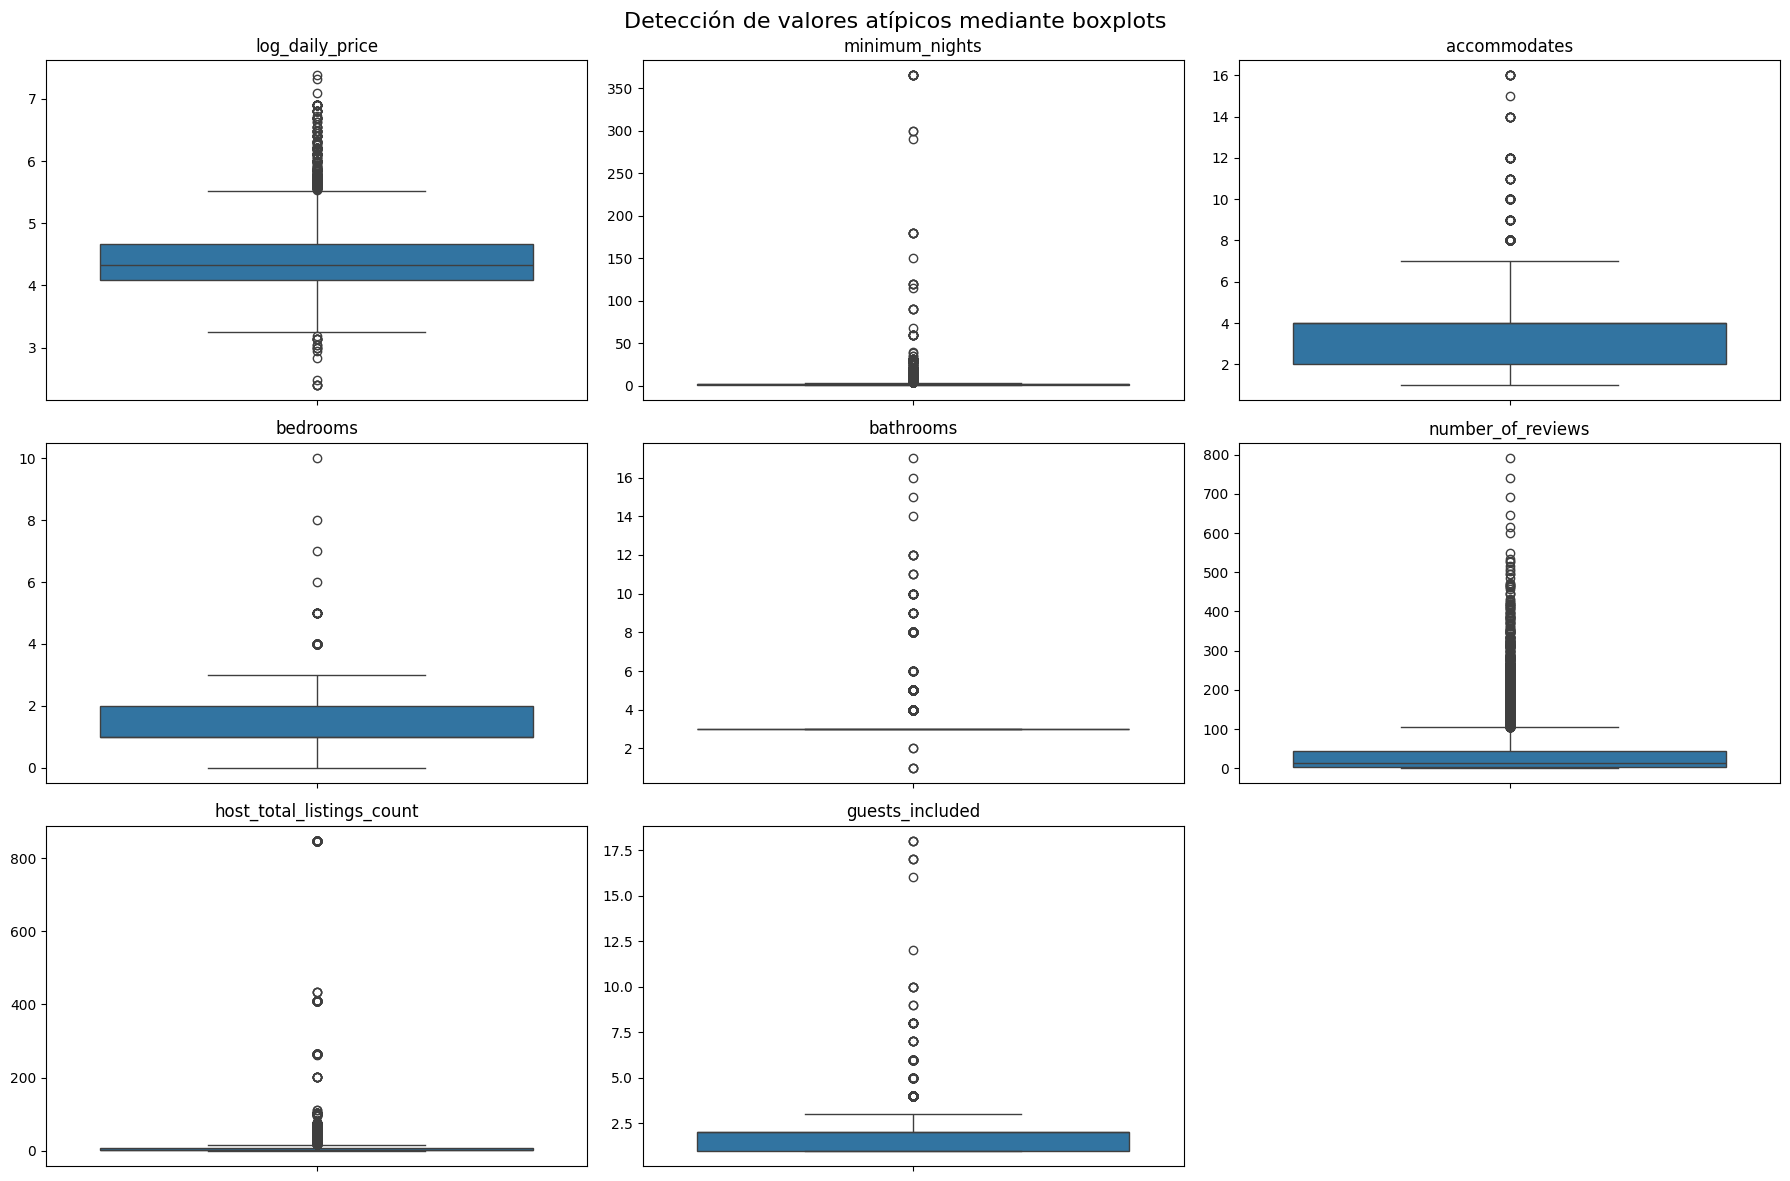

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(variables_numericas) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, variables_numericas):

    sns.boxplot(
        data=df_price_cleaned,
        y=col,
        ax=ax
    )

    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(variables_numericas):]:
    ax.remove()

fig.suptitle(
    "Detección de valores atípicos mediante boxplots",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
def resumen_outliers(df, columnas):
    resultados = []

    for col in columnas:
        x = df[col].dropna()

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        iqr = q3 - q1

        lim_inf = q1 - 1.5 * iqr
        lim_sup = q3 + 1.5 * iqr

        # IQR = 0: criterio no informativo
        if iqr == 0:
            n_outliers = np.nan
            porcentaje = np.nan
        else:
            outliers = (x < lim_inf) | (x > lim_sup)
            n_outliers = outliers.sum()
            porcentaje = outliers.mean() * 100

        resultados.append({
            "variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lim_inf": lim_inf,
            "lim_sup": lim_sup,
            "n_outliers": n_outliers,
            "porcentaje": porcentaje
        })

    return pd.DataFrame(resultados).set_index("variable")


resumen = resumen_outliers(df_price_cleaned, variables_numericas)

display(resumen.round(2))

,Q1,Q3,IQR,lim_inf,lim_sup,n_outliers,porcentaje
variable,,,,,,,
log_daily_price,4.09,4.67,0.58,3.23,5.53,366.0,3.93
minimum_nights,1.00,2.00,1.00,-0.50,3.50,874.0,9.39
accommodates,2.00,4.00,2.00,-1.00,7.00,197.0,2.12
bedrooms,1.00,2.00,1.00,-0.50,3.50,105.0,1.13
bathrooms,3.00,3.00,0.00,3.00,3.00,NaN,NaN
number_of_reviews,4.00,44.00,40.00,-56.00,104.00,982.0,10.55
host_total_listings_count,1.00,7.00,6.00,-8.00,16.00,1595.0,17.13
guests_included,1.00,2.00,1.00,-0.50,3.50,564.0,6.06


Algo extraño pasa con los baños

### Analisis de los baños

In [ ]:
df["bathrooms"].value_counts(dropna=False).sort_index()

,count
bathrooms,
1,3
2,2
3,7863
4,155
5,1122
6,29
8,108
9,10
10,17


In [ ]:
df_raw.loc[
    df_raw["bathrooms"].isin([1, 2, 3, 5]),
    ["bathrooms", "bedrooms", "accommodates"]
].sample(20, random_state=42)

,bathrooms,bedrooms,accommodates
1239,5,2,5
8985,3,3,6
5434,3,1,4
8012,3,0,3
4738,3,1,2
2500,3,0,3
1589,3,1,4
5275,3,0,2
6777,3,1,2
4361,3,1,2


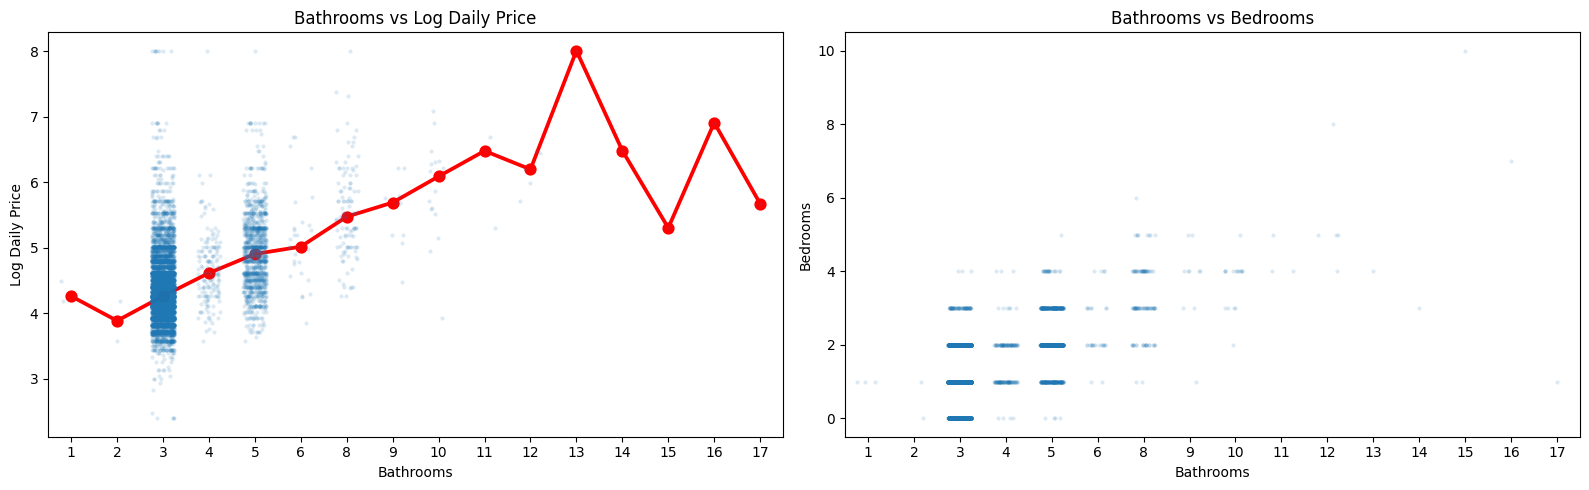

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Bathrooms vs log_daily_price
sns.stripplot(
    data=df,
    x="bathrooms",
    y="log_daily_price",
    jitter=0.25,
    alpha=0.15,
    size=3,
    ax=axes[0]
)

# Agregar medianas por cantidad de baños
sns.pointplot(
    data=df,
    x="bathrooms",
    y="log_daily_price",
    estimator=np.median,
    errorbar=None,
    color="red",
    markers="o",
    linestyles="-",
    ax=axes[0]
)

axes[0].set_title("Bathrooms vs Log Daily Price")
axes[0].set_xlabel("Bathrooms")
axes[0].set_ylabel("Log Daily Price")


# 2. Bathrooms vs Bedrooms
sns.stripplot(
    data=df,
    x="bathrooms",
    y="bedrooms",
    jitter=0.25,
    alpha=0.15,
    size=3,
    ax=axes[1]
)

axes[1].set_title("Bathrooms vs Bedrooms")
axes[1].set_xlabel("Bathrooms")
axes[1].set_ylabel("Bedrooms")

plt.tight_layout()
plt.show()

Observando estos datos decidimos eliminar los registros que no tienen baños entre 3 y 10 por haber menos de 10 datos.

In [ ]:
df_bathrooms_cleaned = df_price_cleaned[
    (df_price_cleaned["bathrooms"] >= 3) & (df_price_cleaned["bathrooms"] <= 10)
].copy()

Resulta que salta el precio de 1600 a 3000. Pareciera ser 3000 un precio máximo.

In [ ]:
from scipy.stats import zscore

col = "log_daily_price"

# Calcular Z-scores
z = pd.Series(
    zscore(df_bathrooms_cleaned[col], nan_policy="omit"),
    index=df_bathrooms_cleaned.index
)

# Identificar valores atípicos
outliers = df_bathrooms_cleaned.loc[z.abs() > 3]

print(f"Outliers: {len(outliers)}")
print(f"Porcentaje: {len(outliers) / df_bathrooms_cleaned[col].notna().sum() * 100:.2f}%")

# Estadísticos de los valores atípicos
display(outliers[col].describe())

Outliers: 129
Porcentaje: 1.39%


,log_daily_price
count,129.000000
mean,6.284281
std,0.837294
min,2.397895
25%,6.216606
50%,6.309918
75%,6.685861
max,7.378384


In [ ]:
display(
    outliers["daily_price"]
    .value_counts()
    .head(15)
)

,count
daily_price,
500,33
1000,14
450,11
600,10
900,8
800,6
650,6
550,5
700,4


## 1.5 Análisis exploratorio

In [ ]:
df = df_bathrooms_cleaned.copy()

### Matriz de correlación

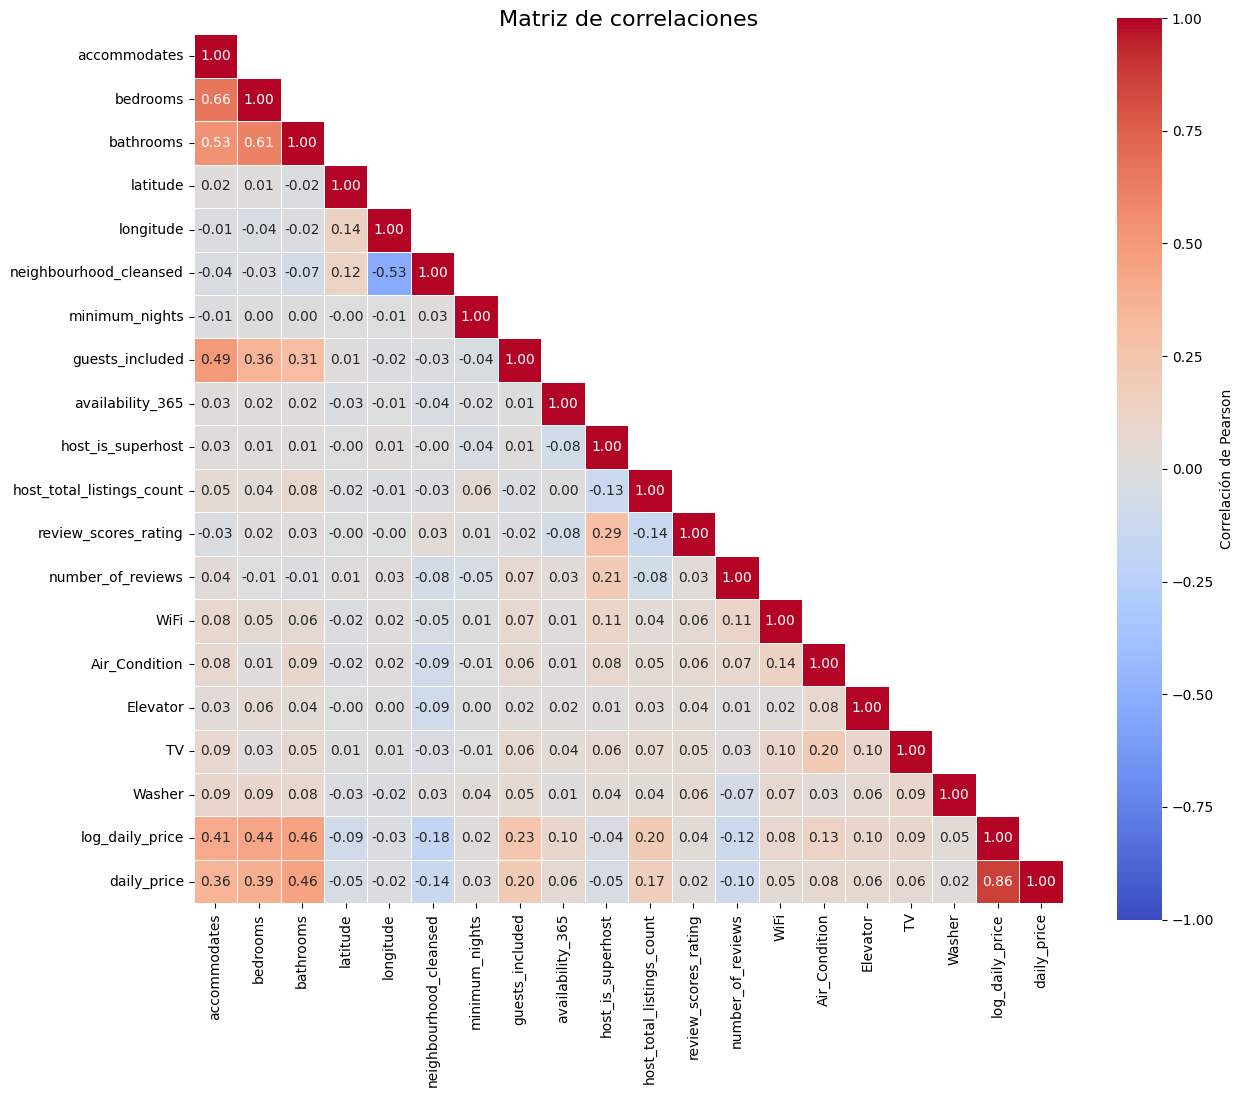

In [ ]:
# Matriz de correlaciones de Pearson
corr = df.corr(method="pearson")

# Ocultar triángulo superior
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(13, 11))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlaciones", fontsize=16)
plt.tight_layout()
plt.show()


### Análisis geográfico

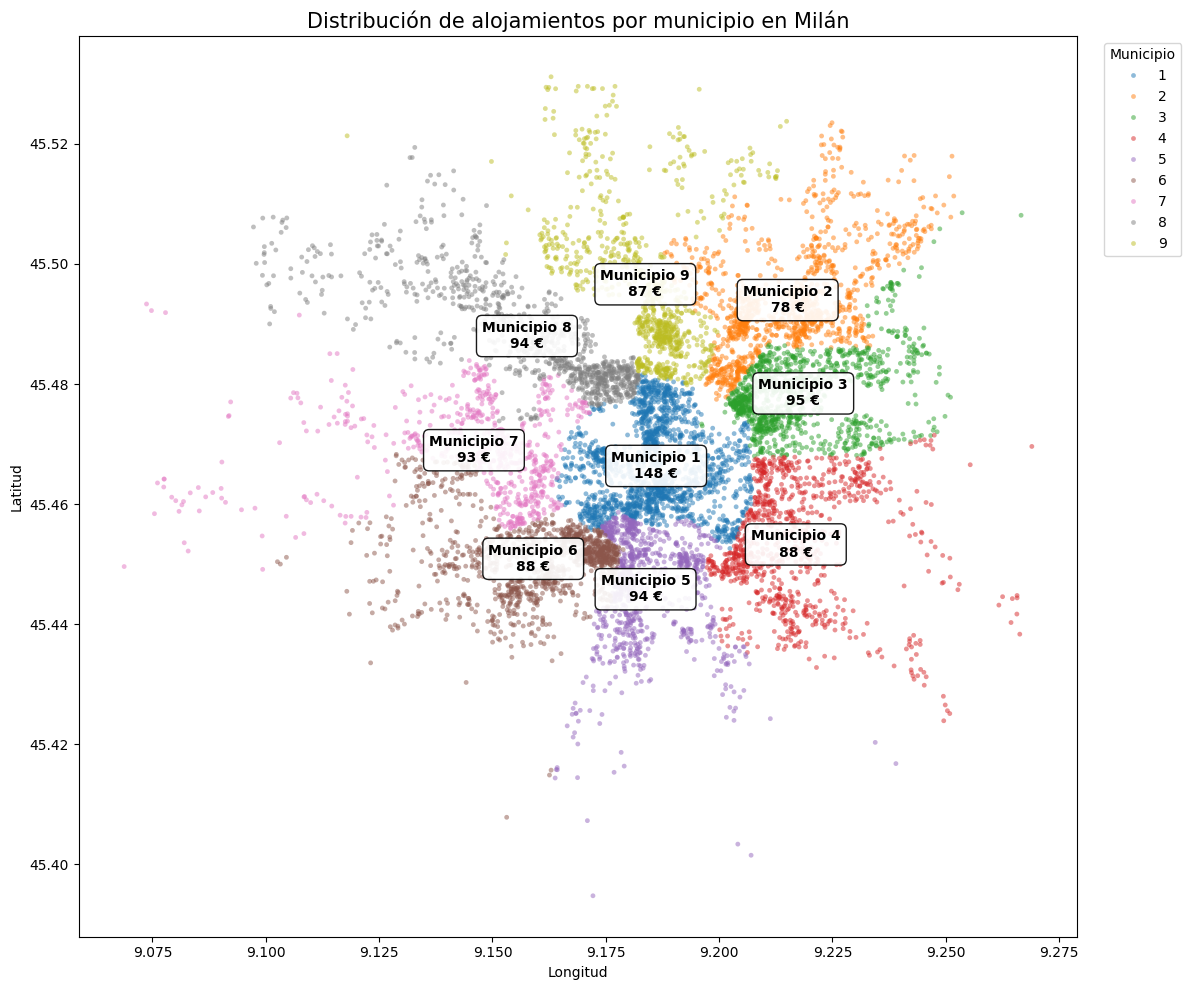

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# Convertir municipios a categorías
data["municipio"] = data["neighbourhood_cleansed"].astype(str)

# Estadísticas por municipio
municipios = (
    data.groupby("municipio")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        precio_medio=("daily_price", "mean"),
    )
    .reset_index()
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 10))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="municipio",
    palette="tab10",
    s=12,
    alpha=0.5,
    linewidth=0,
    ax=ax,
)

# Etiquetas con municipio y precio mediano
for _, row in municipios.iterrows():
    ax.annotate(
        f"Municipio {row['municipio']}\n"
        f"{row['precio_medio']:.0f} €",
        xy=(row["longitude"], row["latitude"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )

ax.set_title(
    "Distribución de alojamientos por municipio en Milán",
    fontsize=15,
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.legend(
    title="Municipio",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


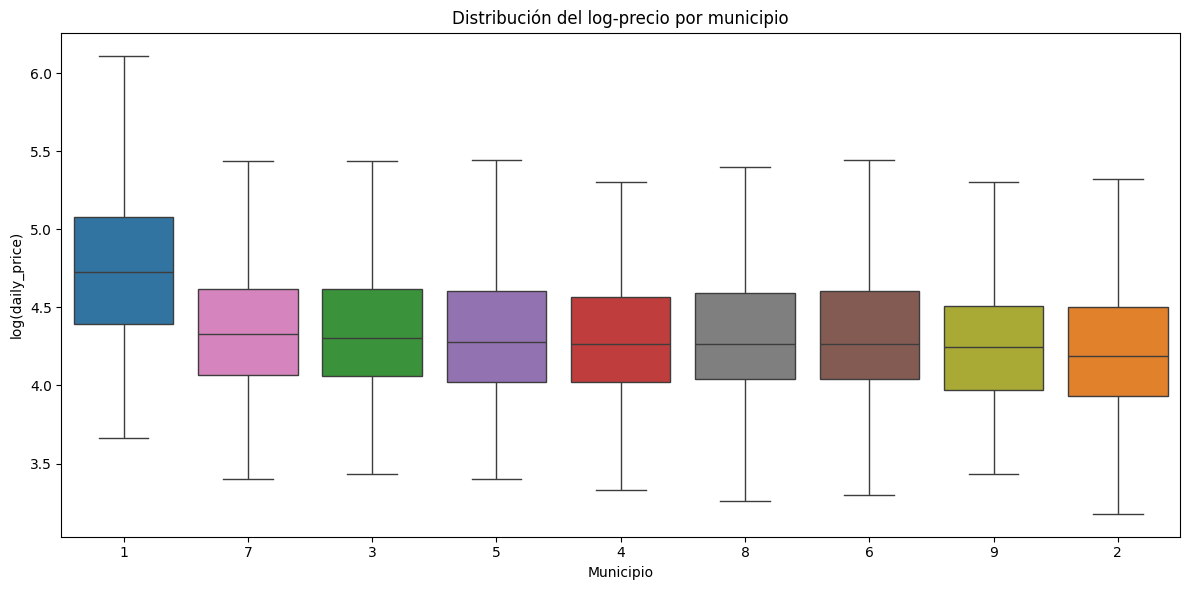

In [ ]:
# Preparación
data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "log_daily_price"]
].dropna().copy()

# Ordenar municipios según el log-precio mediano
orden = (
    data.groupby("neighbourhood_cleansed")["log_daily_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x="neighbourhood_cleansed",
    y="log_daily_price",
    order=orden,
    hue="neighbourhood_cleansed",
    palette="tab10",
    showfliers=False,
    legend=False,
)

plt.title("Distribución del log-precio por municipio")
plt.xlabel("Municipio")
plt.ylabel("log(daily_price)")
plt.tight_layout()
plt.show()

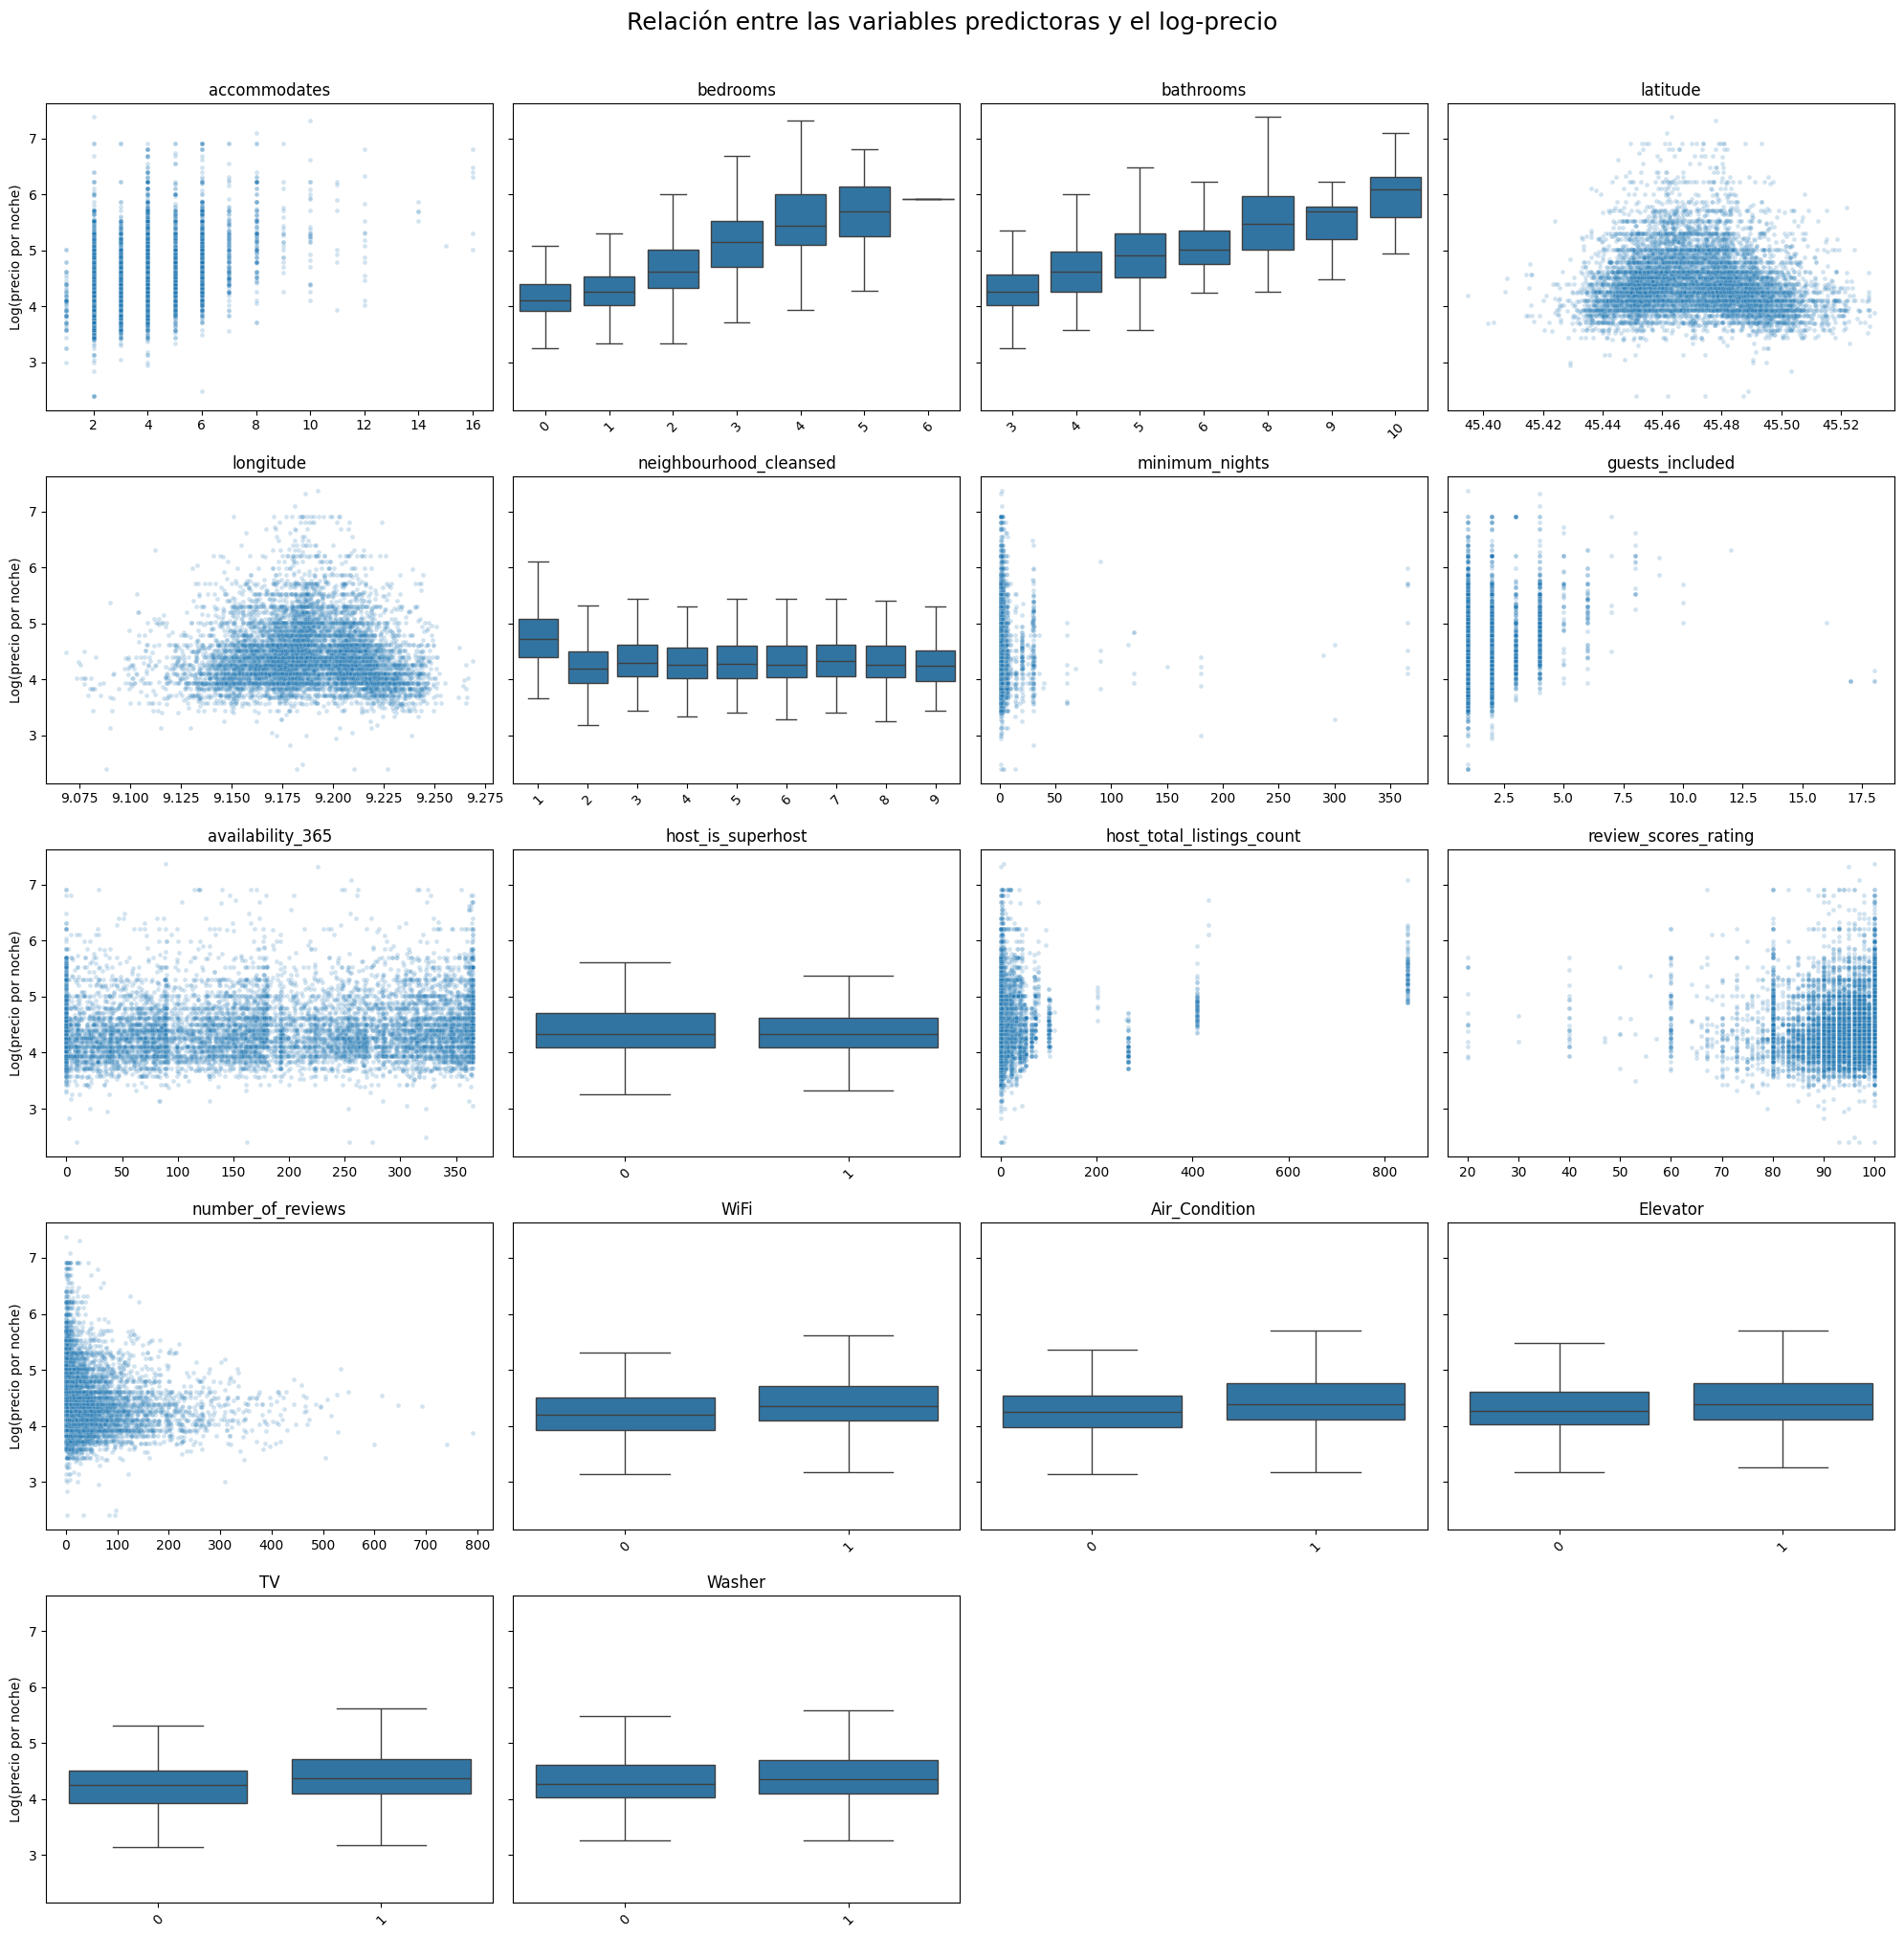

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target = "log_daily_price"

# Excluir los targets
features = df.columns.drop(["daily_price", "log_daily_price"])

# Configuración de la grilla
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    sharey=True
)

axes = axes.flatten()

for ax, col in zip(axes, features):

    # Variables categóricas o discretas con pocos valores
    es_categorica = (
        not pd.api.types.is_numeric_dtype(df[col])
        or col == "neighbourhood_cleansed"
        or df[col].nunique() <= 12
    )

    if es_categorica:
        sns.boxplot(
            data=df,
            x=col,
            y=target,
            showfliers=False,
            ax=ax
        )
        ax.tick_params(axis="x", rotation=45)

    else:
        sns.scatterplot(
            data=df,
            x=col,
            y=target,
            alpha=0.2,
            s=12,
            ax=ax
        )

    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Log(precio por noche)")

# Eliminar ejes sobrantes
for ax in axes[len(features):]:
    ax.remove()

fig.suptitle(
    "Relación entre las variables predictoras y el log-precio",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

# 2. Regresión con OLS

In [ ]:
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split

# Variable objetivo
target = "log_daily_price"

# Variables predictoras
features = df.columns.drop(["daily_price", target]).tolist()

# Variables categóricas
categoricas = ["neighbourhood_cleansed"]

# Construir la fórmula automáticamente
terminos = [
    f"C({col})" if col in categoricas else col
    for col in features
]

formula = f"{target} ~ " + " + ".join(terminos)

print(formula)

log_daily_price ~ accommodates + bedrooms + bathrooms + latitude + longitude + C(neighbourhood_cleansed) + minimum_nights + guests_included + availability_365 + host_is_superhost + host_total_listings_count + review_scores_rating + number_of_reviews + WiFi + Air_Condition + Elevator + TV + Washer


Ajustamos la regresión OLS
Separamos el dataset en entrenamiento (80%) y test (20%). Por ahora, para simplificar, utilizaremos únicamente los registros completos.

In [ ]:
# Eliminar registros con valores faltantes
df_modelo = df[[target] + features].dropna().copy()

print(f"Observaciones disponibles: {len(df_modelo)}")

# Separar entrenamiento y test
df_train, df_test = train_test_split(
    df_modelo,
    test_size=0.2,
    random_state=42
)

# Ajustar modelo OLS
modelo_ols = smf.ols(
    formula=formula,
    data=df_train
).fit()

# Resumen estadístico
print(modelo_ols.summary())

Observaciones disponibles: 9293
                            OLS Regression Results                            
Dep. Variable:        log_daily_price   R-squared:                       0.402
Model:                            OLS   Adj. R-squared:                  0.400
Method:                 Least Squares   F-statistic:                     199.5
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:34:47   Log-Likelihood:                -3975.6
No. Observations:                7434   AIC:                             8003.
Df Residuals:                    7408   BIC:                             8183.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predicciones
y_test = df_test[target]
y_pred = modelo_ols.predict(df_test)

# Métricas
print(f"R²:   {r2_score(y_test, y_pred):.4f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred)**0.5:.4f}")

R²:   0.3800
MAE:  0.3022
RMSE: 0.4168
